<a href="https://colab.research.google.com/github/dierazoc-sys/SD-y-C/blob/main/PUNTO_2_del_TALLER_5_de_SD_y_C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install control

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 578.3/578.3 kB 5.7 MB/s eta 0:00:00


##PRUEBA CON LOS DATOS TEORICOS ENCONTRADOS EN EL TALLER 5

Parámetros iniciales del PID
Kp = 252.0000
Ti = 0.7025 s
Td = 0.1756 s
Ki = 358.7189
Kd = 44.2512

Valor final = 1.0000
Valor máximo = 1.6550
Sobreimpulso Mp = 65.50%


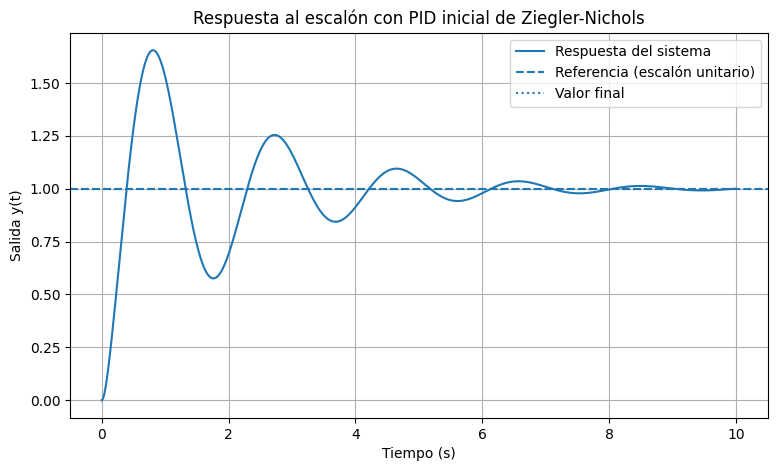

In [2]:

import numpy as np
import matplotlib.pyplot as plt
import control as ct

# 1. Definir la variable s y la planta
s = ct.tf('s')
Gp = 1 / (s * (s + 1) * (s + 20))

# 2. Parámetros iniciales de Ziegler-Nichols
Kp = 252
Ti = 0.7025
Td = 0.1756

# 3. Convertir Ti y Td a Ki y Kd
Ki = Kp / Ti
Kd = Kp * Td

print("Parámetros iniciales del PID")
print(f"Kp = {Kp:.4f}")
print(f"Ti = {Ti:.4f} s")
print(f"Td = {Td:.4f} s")
print(f"Ki = {Ki:.4f}")
print(f"Kd = {Kd:.4f}")

# 4. Construir el controlador PID
Gc = Kp + Ki/s + Kd*s

# 5. Obtener el sistema realimentado
Tcl = ct.feedback(Gc * Gp, 1)

# 6. Simular la respuesta ante un escalón unitario
t = np.linspace(0, 10, 5000)
t, y = ct.step_response(Tcl, T=t)

# 7. Calcular el sobreimpulso
y_final = float(np.real(ct.dcgain(Tcl)))
y_max = np.max(y)
Mp = max(0, (y_max - y_final) / abs(y_final) * 100)

print(f"\nValor final = {y_final:.4f}")
print(f"Valor máximo = {y_max:.4f}")
print(f"Sobreimpulso Mp = {Mp:.2f}%")

# 8. Graficar la respuesta
plt.figure(figsize=(9, 5))
plt.plot(t, y, label="Respuesta del sistema")
plt.axhline(1, linestyle="--", label="Referencia (escalón unitario)")
plt.axhline(y_final, linestyle=":", label="Valor final")
plt.xlabel("Tiempo (s)")
plt.ylabel("Salida y(t)")
plt.title("Respuesta al escalón con PID inicial de Ziegler-Nichols")
plt.grid(True)
plt.legend()
plt.show()


##AJUSTES PARA QUE Mp SEA DEL 15%

PID ajustado:
Kp = 42.9119
Ki = 746.6633
Kd = 475.2969
Sobreimpulso = 15.00%
Polos estables: True


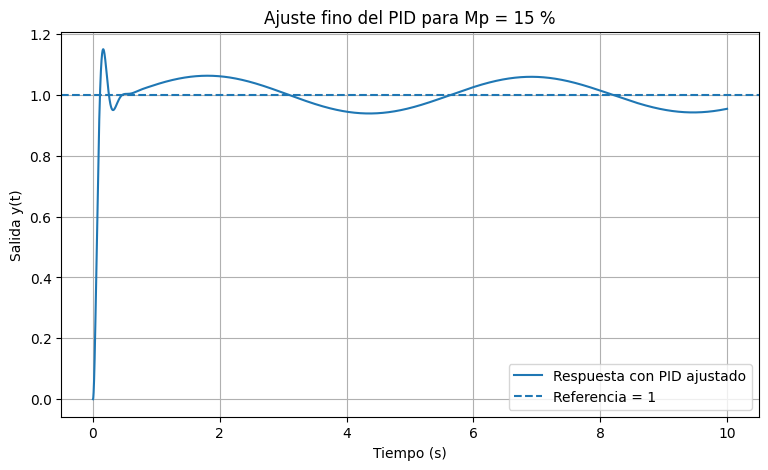

In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.optimize import differential_evolution

# Objetivo de diseño
Mp_objetivo = 15.0
t = np.linspace(0, 10, 10000)

def evaluar_pid(parametros):
    Kp, Ki, Kd = parametros

    # Ecuación característica en lazo cerrado:
    # s^4 + 21s^3 + (20+Kd)s^2 + Kp*s + Ki
    den = [1, 21, 20 + Kd, Kp, Ki]
    polos = np.roots(den)

    # Descartar sistemas inestables
    if np.any(np.real(polos) >= 0):
        return 1e6

    # Función de transferencia en lazo cerrado
    sistema = signal.TransferFunction(
        [Kd, Kp, Ki], den
    )

    _, y = signal.step(sistema, T=t)

    if not np.all(np.isfinite(y)):
        return 1e6

    y_final = 1.0
    Mp = max(0, (np.max(y) - y_final) * 100)

    # Minimizar la diferencia respecto al 15 %
    return (Mp - Mp_objetivo)**2

# Buscar parámetros positivos
resultado = differential_evolution(
    evaluar_pid,
    bounds=[(1, 600), (1, 1000), (1, 600)],
    seed=10,
    maxiter=100,
    popsize=12,
    tol=1e-7
)

Kp_ajustado, Ki_ajustado, Kd_ajustado = resultado.x

# Simular el PID ajustado
den = [
    1, 21, 20 + Kd_ajustado,
    Kp_ajustado, Ki_ajustado
]
sistema = signal.TransferFunction(
    [Kd_ajustado, Kp_ajustado, Ki_ajustado],
    den
)

_, y = signal.step(sistema, T=t)
Mp_final = max(0, (np.max(y) - 1) * 100)

print("PID ajustado:")
print(f"Kp = {Kp_ajustado:.4f}")
print(f"Ki = {Ki_ajustado:.4f}")
print(f"Kd = {Kd_ajustado:.4f}")
print(f"Sobreimpulso = {Mp_final:.2f}%")
print(f"Polos estables: {np.all(np.real(np.roots(den)) < 0)}")

plt.figure(figsize=(9, 5))
plt.plot(t, y, label="Respuesta con PID ajustado")
plt.axhline(1, linestyle="--", label="Referencia = 1")
plt.xlabel("Tiempo (s)")
plt.ylabel("Salida y(t)")
plt.title("Ajuste fino del PID para Mp = 15 %")
plt.grid(True)
plt.legend()
plt.show()



## 📝 Conclusiones

En esta práctica se aplicó el método de **Ziegler–Nichols** para obtener una sintonización inicial del controlador PID de la planta:

$$
G_p(s)=\frac{1}{s(s+1)(s+20)}
$$

La simulación inicial en Python produjo un sobreimpulso del **65,50 %**, superior al valor objetivo del 15 %. Esto evidenció la necesidad de realizar un ajuste fino de los parámetros del controlador.

Mediante un ajuste numérico en Python, se obtuvieron los siguientes valores finales:

| Parámetro | Valor ajustado |
|:---:|---:|
| $K_p$ | 42,9119 |
| $K_i$ | 746,6633 |
| $K_d$ | 475,2969 |
| Sobreimpulso $M_p$ | 15,00 % |

La respuesta ajustada alcanzó el sobreimpulso especificado y la comprobación de los polos indicó que el sistema en lazo cerrado es estable, ya que todos presentan parte real negativa.

### 🔎 Efecto de las constantes del PID

- **Acción proporcional ($K_p$):** influye en la rapidez de respuesta y, si es excesiva, puede incrementar las oscilaciones.
- **Acción integral ($K_i$):** permite reducir el error en estado estacionario, aunque un ajuste excesivo puede afectar el comportamiento transitorio.
- **Acción derivativa ($K_d$):** anticipa los cambios del error y puede contribuir a amortiguar la respuesta.

### ✅ Conclusión final

El método de Ziegler–Nichols proporcionó valores iniciales útiles, pero fue necesario ajustar las constantes mediante simulación para cumplir el requisito de diseño. Este procedimiento permitió comprobar la importancia de combinar el cálculo teórico con la validación computacional para obtener una respuesta que satisfaga las especificaciones establecidas.

**Nota:** aunque se alcanzó el sobreimpulso objetivo y se verificó la estabilidad del modelo, el tiempo de establecimiento debe revisarse por separado para completar la evaluación del desempeño del sistema.
